# Regression on the WEC dataset
This notebook follows one dataset from loading to evaluation. Run the cells from top to bottom.

Change `site` in the next cell to `Adelaide`, `Perth`, `Sydney`, or `Tasmania` and run all cells again to study another site. Keeping the sites separate makes the steps easier to follow and avoids mixing different wave conditions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

site = "Adelaide"
folder = Path("regression_results_simple")
folder.mkdir(exist_ok=True)

## 1. Load the data
There is no header row. The first 32 columns are coordinates. The next 16 are individual buoy powers and are excluded to prevent leakage. The last column is the total power we want to predict.

In [2]:
data = pd.read_csv(f"WECs_DataSet/{site}_Data.csv", header=None)
print("Rows and columns:", data.shape)
print("Missing values:", data.isna().sum().sum())
display(data.head())

# Keep each coordinate layout only once.
data = data.drop_duplicates(subset=list(range(32)))
X = data.iloc[:, :32].to_numpy()
y = data.iloc[:, 48].to_numpy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Rows and columns: (71999, 49)
Missing values: 0
Input shape: (71999, 32)
Target shape: (71999,)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48
0,316.5855,223.9277,182.3434,551.5497,7.8641,243.1339,361.0877,115.9284,78.6087,468.3799,362.6036,1.6865,508.6837,446.6440,385.7292,522.1661,180.9224,366.9186,200.9217,436.4863,189.6325,218.9722,247.9875,269.9356,495.7867,105.5203,141.8014,18.7857,496.6488,3.2835,513.9628,105.5529,78738.9831,86026.8604,69559.8105,99665.7889,74052.5623,79484.3263,85118.6141,82322.0277,98069.1011,86578.6330,93016.4133,63145.1829,98353.1952,80225.1390,98447.2846,97570.2225,1370374.145
1,530.3136,68.7031,31.5983,175.2582,516.1441,63.4652,67.0954,369.4486,14.0930,375.4462,45.4747,361.9118,297.8632,293.7442,90.5536,3.4209,510.7784,564.9436,324.5823,94.5002,424.1370,400.1397,107.3907,248.7212,415.6457,410.1439,156.3712,532.9900,280.7516,559.2803,208.7441,531.3943,97185.2149,98165.3309,72204.3398,72338.9003,87955.8108,89862.0451,64664.9272,83920.1033,80968.0044,87108.1328,68065.1856,99061.3812,77549.1426,99013.1628,78234.4337,84633.6493,1340929.765
2,27.3967,399.0488,565.6854,394.0466,120.2245,558.1293,546.4520,27.3256,314.1051,235.9476,514.9275,26.3633,332.2882,518.8260,494.6027,514.5393,102.5081,221.2811,303.2901,378.8741,85.5374,90.2488,516.1118,498.6277,435.2397,35.5588,148.9206,48.0585,317.9832,26.8732,483.0186,359.0875,76929.3586,77642.1361,100648.5358,82390.5044,71301.6809,100207.0946,97155.1672,97358.7395,93437.7170,69940.2554,92864.1192,60887.8095,72306.6556,81151.1515,83030.9726,94779.6131,1352031.511
3,346.1526,59.6375,226.2742,280.9095,402.2161,218.7181,207.0407,339.5676,0.0000,0.0000,175.5163,365.7745,565.6854,179.4148,155.1914,565.6854,441.9194,560.6924,0.0000,565.6854,424.9487,429.6600,176.7005,217.2239,562.7245,347.2173,0.0000,272.3906,178.4930,317.5044,235.5983,19.6762,95372.9014,99177.8407,83274.9166,97592.6330,98407.2120,86929.3962,77898.1893,80399.3841,89349.6141,85048.3860,70038.2271,92797.3569,97653.8121,74903.3740,71690.6549,96220.4768,1396754.375
4,317.9144,551.8542,335.4745,40.0240,316.6285,365.6434,416.3060,562.1028,211.3577,143.1255,516.7467,288.3794,54.9749,38.8434,193.8276,138.5265,94.6465,256.6874,434.6103,114.7701,0.0000,143.9788,337.7052,536.6741,143.3888,48.6452,109.5254,377.3113,530.8384,463.1129,42.6895,367.9045,74526.6183,97462.1766,93071.6213,77142.7114,74223.9997,87694.8256,91310.7781,97088.1761,81187.3982,63591.6729,92418.1977,82454.8256,97091.7749,85937.5437,66823.1572,93683.0996,1355708.577


## 2. Split and scale
Use 80% for training and 20% for testing. Learn the coordinate means and scales from training data only. Every model uses the same split. We will store test predictions in a dictionary so the final comparison is simple.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

predictions = {}
training_predictions = {}

## 3. Linear regression: scikit-learn OLS
OLS finds the coefficients that minimize the sum of squared errors.

In [4]:
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

predictions["Linear OLS"] = ols.predict(X_test_scaled)
training_predictions["Linear OLS"] = ols.predict(X_train_scaled)

## 4. Linear regression: gradient descent
Start all weights at zero. Calculate the prediction error, then update the weights and intercept. Repeat until the updates become small. We also scale the target here to keep the updates easy to handle. Predictions are converted back to original power units.

A learning rate of 0.01 is deliberately small. The loss curve should decrease and the final predictions should agree closely with OLS.

Iterations: 1858
Largest final gradient: 9.958715288892085e-07


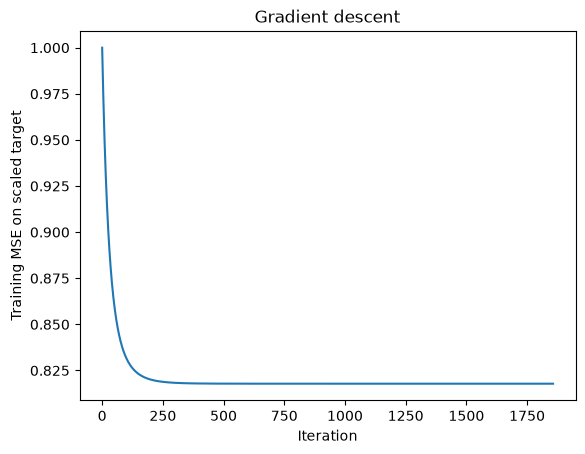

In [5]:
y_mean = y_train.mean()
y_scale = y_train.std()
y_scaled = (y_train - y_mean) / y_scale

weights = np.zeros(32)
intercept = 0.0
learning_rate = 0.01
losses = []
n = len(y_train)

for iteration in range(20000):
    prediction = X_train_scaled @ weights + intercept
    error = prediction - y_scaled

    weight_gradient = (X_train_scaled.T @ error) / n
    intercept_gradient = error.mean()

    weights = weights - learning_rate * weight_gradient
    intercept = intercept - learning_rate * intercept_gradient
    losses.append(np.mean(error ** 2))

    if np.max(np.abs(weight_gradient)) < 0.000001:
        break

print("Iterations:", iteration + 1)
print("Largest final gradient:", np.max(np.abs(weight_gradient)))

train_prediction = X_train_scaled @ weights + intercept
test_prediction = X_test_scaled @ weights + intercept
training_predictions["Linear GD"] = train_prediction * y_scale + y_mean
predictions["Linear GD"] = test_prediction * y_scale + y_mean

plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Training MSE on scaled target")
plt.title("Gradient descent")
plt.show()

## 5. Polynomial regression
Degree 2 adds squares and interactions between coordinates. There are 560 input features after expansion. The test data uses the transformations learned from the training data.

In [6]:
polynomial = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = polynomial.fit_transform(X_train_scaled)
X_test_poly = polynomial.transform(X_test_scaled)

poly_scaler = StandardScaler()
X_train_poly = poly_scaler.fit_transform(X_train_poly)
X_test_poly = poly_scaler.transform(X_test_poly)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

training_predictions["Polynomial degree 2"] = poly_model.predict(X_train_poly)
predictions["Polynomial degree 2"] = poly_model.predict(X_test_poly)
print("Polynomial features:", X_train_poly.shape[1])

Polynomial features: 560


## 6. Choose Ridge alpha using cross-validation
Alpha controls the penalty on large coefficients. For each candidate, train on four folds and validate on the remaining fold. Repeat five times and average the validation MSE. Choose the alpha with the lowest average error.

Each fold has its own scaler to avoid leakage. We use only the original training partition; the final test set is untouched.

In [7]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]
ridge_errors = []

for alpha in ridge_alphas:
    fold_errors = []
    for train_index, valid_index in folds.split(X_train):
        fold_scaler = StandardScaler()
        fold_train = fold_scaler.fit_transform(X_train[train_index])
        fold_valid = fold_scaler.transform(X_train[valid_index])

        model = Ridge(alpha=alpha)
        model.fit(fold_train, y_train[train_index])
        prediction = model.predict(fold_valid)
        fold_errors.append(mean_squared_error(y_train[valid_index], prediction))

    ridge_errors.append(np.mean(fold_errors))

best_ridge_alpha = ridge_alphas[np.argmin(ridge_errors)]
print("Best Ridge alpha:", best_ridge_alpha)
display(pd.DataFrame({"Alpha": ridge_alphas, "CV MSE": ridge_errors}))

Best Ridge alpha: 100


,Alpha,CV MSE
0,0.01,2.564885e+09
1,0.10,2.564885e+09
2,1.00,2.564885e+09
3,10.00,2.564884e+09
4,100.00,2.564878e+09
5,1000.00,2.564975e+09
6,10000.00,2.576156e+09


## 7. Ridge using scikit-learn
Fit again using all training rows and the selected alpha.

In [8]:
ridge = Ridge(alpha=best_ridge_alpha)
ridge.fit(X_train_scaled, y_train)

training_predictions["Ridge sklearn"] = ridge.predict(X_train_scaled)
predictions["Ridge sklearn"] = ridge.predict(X_test_scaled)

## 8. Ridge from scratch
The class has two methods: `fit` learns coefficients and `predict` uses them. Ridge solves `(X.T @ X + alpha * I) @ weights = X.T @ y` after centering the data. Centering allows us to learn an intercept without penalizing it. This matches scikit-learn's Ridge objective.

In [9]:
class RidgeScratch:
    def __init__(self, alpha=1):
        self.alpha = alpha

    def fit(self, X, y):
        X_mean = X.mean(axis=0)
        y_mean = y.mean()
        X_centered = X - X_mean
        y_centered = y - y_mean

        identity = np.eye(X.shape[1])
        left = X_centered.T @ X_centered + self.alpha * identity
        right = X_centered.T @ y_centered
        self.weights = np.linalg.solve(left, right)
        self.intercept = y_mean - X_mean @ self.weights

    def predict(self, X):
        return X @ self.weights + self.intercept

ridge_scratch = RidgeScratch(alpha=best_ridge_alpha)
ridge_scratch.fit(X_train_scaled, y_train)

training_predictions["Ridge scratch"] = ridge_scratch.predict(X_train_scaled)
predictions["Ridge scratch"] = ridge_scratch.predict(X_test_scaled)

## 9. Choose Lasso alpha using cross-validation
Repeat the same procedure for Lasso. Lasso and Ridge use different loss normalizations, so their alpha values are not directly comparable. If the chosen alpha is at either end of a grid, try a wider grid.

In [10]:
lasso_alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]
lasso_errors = []

for alpha in lasso_alphas:
    fold_errors = []
    for train_index, valid_index in folds.split(X_train):
        fold_scaler = StandardScaler()
        fold_train = fold_scaler.fit_transform(X_train[train_index])
        fold_valid = fold_scaler.transform(X_train[valid_index])

        model = Lasso(alpha=alpha, max_iter=10000, tol=1e-7)
        model.fit(fold_train, y_train[train_index])
        prediction = model.predict(fold_valid)
        fold_errors.append(mean_squared_error(y_train[valid_index], prediction))

    lasso_errors.append(np.mean(fold_errors))

best_lasso_alpha = lasso_alphas[np.argmin(lasso_errors)]
print("Best Lasso alpha:", best_lasso_alpha)
display(pd.DataFrame({"Alpha": lasso_alphas, "CV MSE": lasso_errors}))

Best Lasso alpha: 1


,Alpha,CV MSE
0,0.01,2.564885e+09
1,0.10,2.564885e+09
2,1.00,2.564885e+09
3,10.00,2.564885e+09
4,100.00,2.565117e+09
5,1000.00,2.588252e+09
6,10000.00,3.132916e+09


## 10. Lasso using scikit-learn

In [11]:
lasso = Lasso(alpha=best_lasso_alpha, max_iter=10000, tol=1e-7)
lasso.fit(X_train_scaled, y_train)

training_predictions["Lasso sklearn"] = lasso.predict(X_train_scaled)
predictions["Lasso sklearn"] = lasso.predict(X_test_scaled)

## 11. Lasso from scratch
Lasso minimizes `mean(error ** 2) / 2 + alpha * sum(abs(weights))`.

We update one coefficient at a time. For each update, calculate the remaining relationship with the target, then shrink it towards zero by alpha. This is called soft thresholding. A coefficient can become exactly zero.

`gram` stores relationships between input columns and `target_relation` stores their relationships with the target. Computing these once avoids repeatedly scanning every row.

In [12]:
class LassoScratch:
    def __init__(self, alpha=1, max_iter=10000):
        self.alpha = alpha
        self.max_iter = max_iter

    def fit(self, X, y):
        X_mean = X.mean(axis=0)
        y_mean = y.mean()
        X_centered = X - X_mean
        y_centered = y - y_mean

        n = len(y)
        gram = X_centered.T @ X_centered / n
        target_relation = X_centered.T @ y_centered / n
        self.weights = np.zeros(X.shape[1])

        for iteration in range(self.max_iter):
            old_weights = self.weights.copy()
            for j in range(X.shape[1]):
                if gram[j, j] == 0:
                    continue
                value = target_relation[j] - gram[j] @ self.weights
                value = value + gram[j, j] * self.weights[j]

                if value > self.alpha:
                    self.weights[j] = (value - self.alpha) / gram[j, j]
                elif value < -self.alpha:
                    self.weights[j] = (value + self.alpha) / gram[j, j]
                else:
                    self.weights[j] = 0

            change = np.max(np.abs(self.weights - old_weights))
            if change < 0.000001:
                break

        self.iterations = iteration + 1
        self.intercept = y_mean - X_mean @ self.weights
        if self.iterations == self.max_iter:
            print("Lasso reached the iteration limit; check convergence.")

    def predict(self, X):
        return X @ self.weights + self.intercept

lasso_scratch = LassoScratch(alpha=best_lasso_alpha)
lasso_scratch.fit(X_train_scaled, y_train)

training_predictions["Lasso scratch"] = lasso_scratch.predict(X_train_scaled)
predictions["Lasso scratch"] = lasso_scratch.predict(X_test_scaled)
print("Scratch Lasso iterations:", lasso_scratch.iterations)

Scratch Lasso iterations: 26


## 12. Compare every model
MSE is the average squared prediction error. RMSE is its square root, in the same units as power. Lower is better for both. R? measures performance relative to predicting the test-set mean; higher is better and negative values are possible.

The selected alpha is shared by each library/scratch pair because the two implementations solve the same objective.

OLS / GD prediction difference: 1.149170987540856
Ridge prediction difference: 2.3283064365386963e-10
Lasso prediction difference: 0.002746994374319911


,Model,Test MSE,Test RMSE,Test R2,Train RMSE
2,Polynomial degree 2,4.951258e+08,22251.421446,0.842945,21649.756231
5,Lasso sklearn,2.612457e+09,51112.201467,0.171323,50617.532147
6,Lasso scratch,2.612457e+09,51112.201472,0.171323,50617.532147
1,Linear GD,2.612461e+09,51112.240181,0.171322,50617.531872
0,Linear OLS,2.612461e+09,51112.241246,0.171322,50617.531871
3,Ridge sklearn,2.612468e+09,51112.304591,0.171320,50617.543086
4,Ridge scratch,2.612468e+09,51112.304591,0.171320,50617.543086


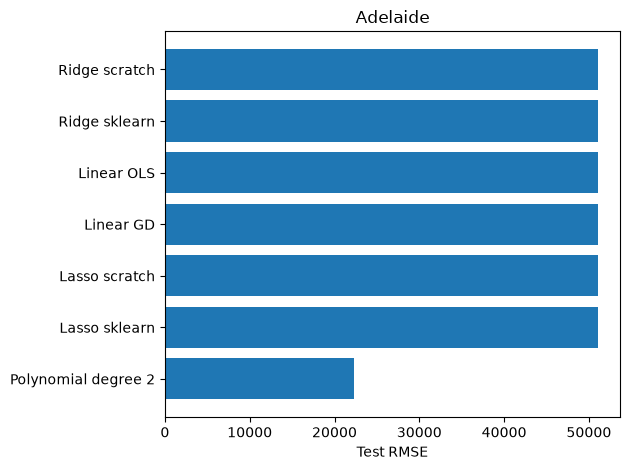

In [13]:
rows = []
for name in predictions:
    mse = mean_squared_error(y_test, predictions[name])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[name])
    train_rmse = np.sqrt(mean_squared_error(y_train, training_predictions[name]))
    rows.append([name, mse, rmse, r2, train_rmse])

comparison = pd.DataFrame(rows, columns=["Model", "Test MSE", "Test RMSE", "Test R2", "Train RMSE"])
comparison = comparison.sort_values("Test RMSE")
display(comparison)
comparison.to_csv(folder / f"{site}_comparison.csv", index=False)

plt.barh(comparison["Model"], comparison["Test RMSE"])
plt.xlabel("Test RMSE")
plt.title(site)
plt.tight_layout()
plt.show()

print("OLS / GD prediction difference:", np.max(np.abs(predictions["Linear OLS"] - predictions["Linear GD"])))
print("Ridge prediction difference:", np.max(np.abs(predictions["Ridge sklearn"] - predictions["Ridge scratch"])))
print("Lasso prediction difference:", np.max(np.abs(predictions["Lasso sklearn"] - predictions["Lasso scratch"])))

## 13. Show underfitting and overfitting
Use 200 examples from the original training partition and a separate validation set, leaving the test set out of this experiment.

A constant prediction has very low capacity and illustrates underfitting. Linear regression has 32 features. Quadratic regression has 560 features, so it can memorize 200 examples and overfit. Check the measured train/validation errors rather than assuming a particular result.

In [14]:
X_small, X_valid, y_small, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)
X_small = X_small[:200]
y_small = y_small[:200]
X_valid = X_valid[:3000]
y_valid = y_valid[:3000]

constant_train = np.full(len(y_small), y_small.mean())
constant_valid = np.full(len(y_valid), y_small.mean())

small_scaler = StandardScaler()
small_train = small_scaler.fit_transform(X_small)
small_valid = small_scaler.transform(X_valid)

small_linear = LinearRegression()
small_linear.fit(small_train, y_small)
linear_train = small_linear.predict(small_train)
linear_valid = small_linear.predict(small_valid)

small_poly = PolynomialFeatures(2, include_bias=False)
poly_train = small_poly.fit_transform(small_train)
poly_valid = small_poly.transform(small_valid)

small_quadratic = LinearRegression()
small_quadratic.fit(poly_train, y_small)
quadratic_train = small_quadratic.predict(poly_train)
quadratic_valid = small_quadratic.predict(poly_valid)

,Model,Train RMSE,Validation RMSE
0,Constant,5.622346e+04,55494.183676
1,Linear,4.541062e+04,55554.585986
2,Quadratic,1.825903e-10,48157.008816


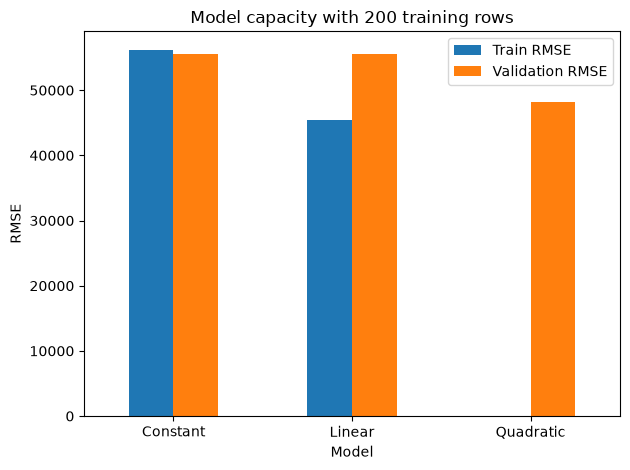

In [15]:
names = ["Constant", "Linear", "Quadratic"]
train_values = [constant_train, linear_train, quadratic_train]
valid_values = [constant_valid, linear_valid, quadratic_valid]
capacity_rows = []

for i in range(3):
    train_rmse = np.sqrt(mean_squared_error(y_small, train_values[i]))
    valid_rmse = np.sqrt(mean_squared_error(y_valid, valid_values[i]))
    capacity_rows.append([names[i], train_rmse, valid_rmse])

capacity = pd.DataFrame(capacity_rows, columns=["Model", "Train RMSE", "Validation RMSE"])
display(capacity)
capacity.to_csv(folder / f"{site}_capacity.csv", index=False)
capacity.plot(x="Model", y=["Train RMSE", "Validation RMSE"], kind="bar", rot=0)
plt.ylabel("RMSE")
plt.title("Model capacity with 200 training rows")
plt.tight_layout()
plt.show()

## Reading your results
- Underfitting: the constant model has high training and validation errors.
- Overfitting: the small quadratic model can have almost zero training error but much larger validation error.
- Compare the full-data quadratic model with this small-data experiment to see the benefit of more training examples.
- Use the comparison table to discuss which model has the lowest test error for this site.
- Change `site` at the top and run again for the other three files. Each site's comparison is saved separately.

These results describe a random split of layouts at an existing site. They do not measure generalization to an unseen wave site.